In [19]:
#Instalasi dan Import Pustaka
!pip install -q pyspark
import pyspark
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, to_timestamp, date_trunc, count, hour, dayofweek, when, sum as _sum

#Inisialisasi SparkSession
spark = SparkSession.builder.appName('LCL_Load_Forecasting').getOrCreate()

#Memuat Data
path_block0 = "/content/sample_data/block_0.csv"
path_weather = "/content/sample_data/weather_hourly_darksky.csv"

#Membaca berkas secara terpisah (tanpa inferSchema agar cepat)
df_block0 = spark.read.csv(path_block0, header=True, sep=',')
df_weather = spark.read.csv(path_weather, header=True, sep=',')

display(df_block0.limit(5).toPandas())
display(df_weather.limit(5).toPandas())

,LCLid,tstp,energy(kWh/hh)
0,MAC000002,2012-10-12 00:30:00.0000000,0
1,MAC000002,2012-10-12 01:00:00.0000000,0
2,MAC000002,2012-10-12 01:30:00.0000000,0
3,MAC000002,2012-10-12 02:00:00.0000000,0
4,MAC000002,2012-10-12 02:30:00.0000000,0


,visibility,windBearing,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,5.97,104,10.24,2011-11-11 00:00:00,8.86,1016.76,10.24,2.77,rain,partly-cloudy-night,0.91,Partly Cloudy
1,4.88,99,9.76,2011-11-11 01:00:00,8.83,1016.63,8.24,2.95,rain,partly-cloudy-night,0.94,Partly Cloudy
2,3.7,98,9.46,2011-11-11 02:00:00,8.79,1016.36,7.76,3.17,rain,partly-cloudy-night,0.96,Partly Cloudy
3,3.12,99,9.23,2011-11-11 03:00:00,8.63,1016.28,7.44,3.25,rain,fog,0.96,Foggy
4,1.85,111,9.26,2011-11-11 04:00:00,9.21,1015.98,7.24,3.7,rain,fog,1.0,Foggy


## Pembersihan, Agregasi, dan Penggabungan Data (Data Cleaning & Join)
Sesuai prosedur jurnal Ali et al. (2024), data yang mengandung nilai Null atau string kosong harus dibuang. Setelah bersih, data timestamp dikonversi dan dibulatkan ke skala jam untuk memungkinkan agregasi (penjumlahan energi per jam). Setelah data energi memiliki resolusi per jam, data digabungkan (inner join) dengan data cuaca. Terakhir, kita menyaring nilai energi 0 yang diakibatkan oleh anomali seperti pemadaman listrik.

In [20]:
#Pembersihan data 'Null' dan konversi timestamp
df_block0_cleaned = df_block0.filter(
    col("`energy(kWh/hh)`").isNotNull() &
    (col("`energy(kWh/hh)`") != "Null") &
    (col("`energy(kWh/hh)`") != "null")
).withColumn("energy_double", col("`energy(kWh/hh)`").cast("double")) \
 .withColumn("timestamp", to_timestamp("tstp")) \
 .withColumn("hour_time", date_trunc("hour", "timestamp"))

#Format timestamp data cuaca
df_weather_formatted = df_weather.withColumn("hour_time", to_timestamp("time"))

#Agregasi data energi per jam
df_block0_hourly = df_block0_cleaned.groupBy("hour_time").agg(
    _sum("energy_double").alias("sum_energy"),
    count("LCLid").alias("count_lcl")
)

#Penggabungan data (Join) dan Penyaringan Anomali (Energi <= 0)
df_merged = df_block0_hourly.join(df_weather_formatted, on="hour_time", how="inner")
df_cleaned = df_merged.filter(col("sum_energy") > 0)

print(f"Data siap dianalisis: {df_cleaned.count()} baris")

Data siap dianalisis: 19622 baris


## Analisis Deskriptif dan Rekayasa Fitur
Kita mendaftarkan data bersih sebagai Temp View SQL untuk menganalisis pola rata-rata konsumsi per jam. Selanjutnya, kita melakukan Feature Engineering untuk mengekstrak fitur masukan yang dibutuhkan model: Jumlah Meteran (count_lcl_feat), Suhu Udara (temp_feat), Jam (hour_feat), Akhir Pekan (weekend_feat), dan Target Konsumsi (label).

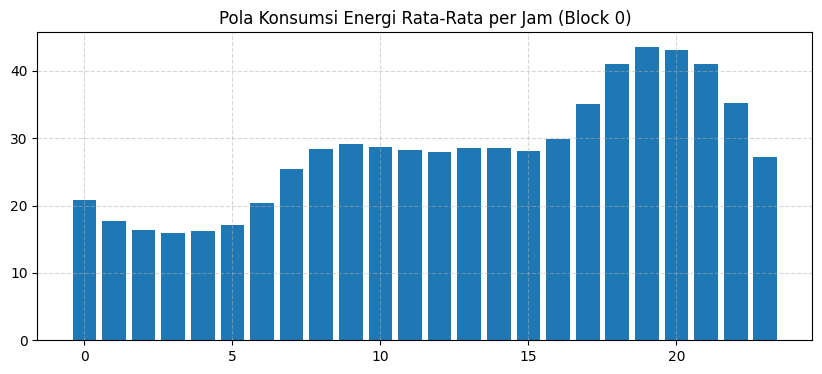

In [21]:
# 1. Analisis Deskriptif (Spark SQL)
df_cleaned.createOrReplaceTempView("lcl_hourly")
hourly_pattern = spark.sql("""
    SELECT
        hour(hour_time) AS hour_of_day,
        AVG(sum_energy) AS avg_energy
    FROM lcl_hourly
    GROUP BY hour(hour_time)
    ORDER BY hour_of_day
""")

# Visualisasi Sederhana
df_pattern_pd = hourly_pattern.toPandas()
plt.figure(figsize=(10, 4))
plt.bar(df_pattern_pd['hour_of_day'], df_pattern_pd['avg_energy'])
plt.title('Pola Konsumsi Energi Rata-Rata per Jam (Block 0)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Ekstraksi Fitur (Feature Engineering)
df_features = df_cleaned.withColumn("hour_feat", hour("hour_time")) \
                        .withColumn("day_of_week", dayofweek("hour_time")) \
                        .withColumn("weekend_feat", when((col("day_of_week") == 1) | (col("day_of_week") == 7), 1).otherwise(0)) \
                        .withColumn("temp_feat", col("temperature").cast("double"))

df_ml_ready = df_features.select(
    col("count_lcl").alias("count_lcl_feat"),
    "temp_feat",
    "hour_feat",
    "weekend_feat",
    col("sum_energy").alias("label")
)

##Persiapan Data Machine Learning (Vektorisasi dan Penskalaan)
Algoritma di PySpark MLlib mensyaratkan seluruh fitur masukan digabungkan menjadi satu kolom vektor tunggal menggunakan VectorAssembler. Karena skala nilai dari setiap fitur berbeda (misal: jam bernilai 0-23, sedangkan jumlah meteran bernilai ~100), kita wajib menstandardisasi nilainya menggunakan StandardScaler. Data kemudian dipecah menjadi Training Set (80%) dan Testing Set (20%) dengan seed tetap agar reprodusibel.

In [22]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

#Menggabungkan fitur ke dalam satu vektor
assembler = VectorAssembler(
    inputCols=["count_lcl_feat", "temp_feat", "hour_feat", "weekend_feat"],
    outputCol="raw_features"
)
df_vectorized = assembler.transform(df_ml_ready)

#Menstandardisasi nilai (Scaling)
scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withStd=True, withMean=True)
scaler_model = scaler.fit(df_vectorized)
df_scaled = scaler_model.transform(df_vectorized)

#Train-Test Split (seed 42 agar hasil selalu konsisten)
train_data, test_data = df_scaled.randomSplit([0.8, 0.2], seed=42)

print(f"Data Latih: {train_data.count()} baris")
print(f"Data Uji: {test_data.count()} baris")

Data Latih: 15750 baris
Data Uji: 3872 baris


##Pelatihan Model Ridge Regression dan Evaluasi
Berdasarkan rekomendasi jurnal Ali et al. (2024), model yang terregularisasi seperti Ridge Regression memiliki performa fitting waktu yang efisien serta mencegah overfitting. Pada PySpark, Ridge Regression didefinisikan menggunakan kelas LinearRegression dengan parameter elasticNetParam = 0.0. Setelah dilatih, model dievaluasi untuk mendapatkan metrik $R^2$, RMSE, dan MAE.

In [23]:
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

#Inisialisasi & Pelatihan Model Ridge Regression
ridge_algo = LinearRegression(featuresCol="scaled_features", labelCol="label",
                              elasticNetParam=0.0, regParam=0.01)

ridge_model = ridge_algo.fit(train_data)

#Melakukan Prediksi pada Data Uji
predictions = ridge_model.transform(test_data)

#Evaluasi Metrik
evaluator_r2 = RegressionEvaluator(predictionCol="prediction", labelCol="label", metricName="r2")
evaluator_rmse = RegressionEvaluator(predictionCol="prediction", labelCol="label", metricName="rmse")
evaluator_mae = RegressionEvaluator(predictionCol="prediction", labelCol="label", metricName="mae")

r2_score = evaluator_r2.evaluate(predictions)
rmse_score = evaluator_rmse.evaluate(predictions)
mae_score = evaluator_mae.evaluate(predictions)

print("--- Hasil Evaluasi Ridge Regression ---")
print(f"R Squared (R2) : {r2_score:.4f}")
print(f"RMSE           : {rmse_score:.4f}")
print(f"MAE            : {mae_score:.4f}")

--- Hasil Evaluasi Ridge Regression ---
R Squared (R2) : 0.7895
RMSE           : 9.6417
MAE            : 7.5922
